# 19. What the reader sees: CTC columns and the app's real OCR output

This notebook answers three questions with real crops:

1. **What does the server reader actually look at?** The crop after resizing.
2. **What is a CTC column, and why does a line lose letters when there are too few of them?**
3. **What does the real app output on the fresh photos, compared with hand-cut crops?**

Nothing is trained. It reads a few crops on CPU with the exported readers (a minute or two) and loads saved results
for everything else. The readers:

| Name | What it is |
|---|---|
| S0 | Server reader fine-tuned on our whiteboard data, guidance on (only the NRTR loss trains the backbone) |
| G0 | The same, guidance off (the CTC loss also trains the backbone) |
| S1his | The model trained on the teammate's 80:10:10 split |

Saved results come from `board2notes_freshwriter_test_20261111/weakness_diagnosis_20261112/` (12 Nov).

In [1]:
from pathlib import Path
import sys, json, csv, math, difflib, collections
import numpy as np, cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon
from IPython.display import display, Markdown


def find_assignment():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'board2notes_ocr_package').is_dir() and (p / 'board2notes_freshwriter_test_20261111').is_dir():
            return p
    raise FileNotFoundError('Open this notebook from inside the Assignment folder.')


A = find_assignment()
sys.path.insert(0, str(A / 'board2notes_ocr_package' / 'b2n_ocr'))
import ocr_backend as ob                      # the app's own reader code (same resize and decoding as the app)
from preprocessing import text_lines as tl    # the app's own crop code

ob.MODELS.update({
    'S0': A / 'results_strategies_s0s3/results/models/PP-OCRv5_server_rec_board2notes_S0',
    'G0': A / 'results_guide_g0/results/models/PP-OCRv5_server_rec_board2notes_G0',
    'S1his': A / 'results_server_his_20261110/results/models/PP-OCRv5_server_rec',
})
NW = A / 'board2notes_newwriter_test_20261107'
FR = A / 'board2notes_freshwriter_test_20261111'
DIAG = FR / 'weakness_diagnosis_20261112'
PHOTOS = A / '1111_unfamiliar'
readers = {m: ob.RecognitionModel(m, threads=4) for m in ('S0', 'G0')}
print('Assignment folder:', A)
print('reader input shape (channels, height, minimum width):', readers['G0'].shape)

/sessions/rcw-01vkkhtsx22qwuxufc3jfk4j/.local/lib/python3.10/site-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Assignment folder: /sessions/rcw-01vkkhtsx22qwuxufc3jfk4j/mnt/Computer Vision & Deep Learning/Assignment
reader input shape (channels, height, minimum width): [3, 64, 1024]


## 1. Two helper functions

`ctc_columns` runs one crop through a reader and keeps **everything** the CTC head outputs, not just the final text.
`show_columns` draws it. You don't need to read the code to follow the pictures; the next section explains them.

In [2]:
def needed(label):
    # columns CTC needs: one per character, plus one blank between two identical neighbours ("ll", "ss", "ee")
    t = ' '.join(label.split())
    return len(t) + sum(a == b for a, b in zip(t, t[1:]))


def ctc_columns(rec, img):
    rec.read([img])                                   # builds the character table on first use
    x = ob.resize_for_reader(img, rec.shape)          # exactly what the app feeds the reader
    rec.input.reshape([1, *x.shape]); rec.input.copy_from_cpu(x[None]); rec.predictor.run()
    prob = rec.output.copy_to_cpu()[0]                # one row per column, one value per character (+ blank)
    idx = prob.argmax(-1)
    emit = [i for i, v in enumerate(idx) if v != 0 and (i == 0 or v != idx[i - 1])]
    text = ''.join(rec.table[int(idx[i])] for i in emit)
    h, w = img.shape[:2]
    ink_px = min(x.shape[2], math.ceil(rec.shape[1] * w / h))   # resized width of the real crop (rest is padding)
    stride = x.shape[2] / prob.shape[0]                          # input pixels per column
    return dict(x=x, prob=prob, idx=idx, emit=emit, text=text, stride=stride, ink_px=ink_px,
                ink_cols=math.ceil(ink_px / stride), table=rec.table)


def char(r, i):
    return '·' if r['idx'][i] == 0 else (r['table'][int(r['idx'][i])] if r['table'][int(r['idx'][i])] != ' ' else '␣')


def show_columns(img, r, title, per_row=56, mark=()):
    # top: the image exactly as the reader sees it, cut into columns; above each column, the character it chose
    #   bold black = a new character is written here; grey = same as the column before (merged); '·' = blank
    # bottom bars: how sure the column is (top probability, 0 to 1)
    x = ((r['x'].transpose(1, 2, 0) * .5 + .5) * 255).clip(0, 255).astype(np.uint8)[:, :, ::-1]
    n = r['ink_cols']; s = r['stride']; H = x.shape[0]
    rows = math.ceil(n / per_row)
    fig, axes = plt.subplots(rows, 1, figsize=(18, 4.4 * rows), squeeze=False, dpi=90)
    emit = set(r['emit'])
    for k in range(rows):
        ax = axes[k, 0]; c0, c1 = k * per_row, min(n, (k + 1) * per_row)
        ax.imshow(x[:, int(c0 * s):int(c1 * s)], extent=(c0 * s, c1 * s, H, 0), aspect='equal')
        for i in range(c0, c1):
            e = i in emit
            if e:
                ax.add_patch(Rectangle((i * s, 0), s, H, color='#2ca02c', alpha=.18, lw=0))
            if i in mark:
                ax.add_patch(Rectangle((i * s, 0), s, H, fill=False, ec='red', lw=2))
            ax.axvline(i * s, color='#1f77b4', lw=.4, alpha=.6)
            ax.text((i + .5) * s, -4, char(r, i), ha='center', va='bottom', fontsize=10 if e else 8,
                    color='black' if e else ('#bbbbbb' if r['idx'][i] == 0 else '#888888'),
                    fontweight='bold' if e else 'normal', family='DejaVu Sans Mono')
            p = float(r['prob'][i].max())
            ax.add_patch(Rectangle((i * s + 1, H + 26 - 22 * p), s - 2, 22 * p, color='#ff7f0e', lw=0))
        ax.set_xlim(c0 * s, max(c1, c0 + per_row) * s); ax.set_ylim(H + 28, -22); ax.axis('off')
    axes[0, 0].set_title(title, loc='left', fontsize=12)
    plt.tight_layout(); plt.show()


def topk(r, i, k=3):
    p = r['prob'][i]; o = np.argsort(p)[::-1][:k]
    return ', '.join(f"'{r['table'][int(j)] or '·'}' {p[j]:.2f}" for j in o)


new_writers = {row['path']: row['label'] for row in csv.DictReader(open(NW / 'manifest.csv', encoding='utf-8'))}

## 2. What happens to a crop before the reader sees it

The reader never sees the crop at its own size.
1. It is **resized to 64 px tall**, and the width is scaled by the same factor, so the letters keep their shape.
2. If the result is narrower than 1024 px, black padding is added on the right.

The backbone then turns every **8 px of width** into one **column**. Each column answers one question: "which
character is here, or nothing (blank)?" The text comes from these columns:

1. Pick each column's most likely answer: `t t · h h · a t t`
2. Merge neighbours that are the same: `t · h · a t`
3. Drop the blanks: `that`

That is **CTC greedy decoding**: exactly what the app does.

**The consequence:**
- One column can write at most one character.
- Two identical letters in a row ("ll", "ss") need a blank between them, so they cost an extra column.

So if a crop gives fewer columns than the line has characters, the reader **cannot** write the whole line. Some
letters must be dropped, however well the model was trained. "Room" below means columns ÷ characters needed.

**Tall, narrow crops have the least room.** The crop is shrunk to 64 px tall, so a line whose crop has a lot of
height for its width is squeezed into very few columns. The two causes are big handwriting with cramped letters,
and loose cropping with empty space above and below.

label: 'that allows the attacker complete control of the computer'
crop 1148 x 211 px  ->  resized to 349 x 64 px  ->  44 columns
characters needed: 59   room = 0.75  (below 1: letters must be lost)


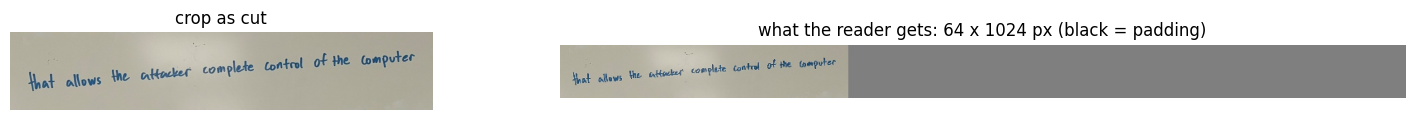

In [3]:
key = 'images/jhs__train__JH6.2.jpg'
img = cv2.imread(str(NW / key)); label = new_writers[key]
r = ctc_columns(readers['G0'], img)
print(f"label: {label!r}")
print(f"crop {img.shape[1]} x {img.shape[0]} px  ->  resized to {r['ink_px']} x 64 px  ->  {r['ink_cols']} columns")
print(f"characters needed: {needed(label)}   room = {r['ink_cols'] / needed(label):.2f}  (below 1: letters must be lost)")
fig, ax = plt.subplots(1, 2, figsize=(18, 2.6), gridspec_kw=dict(width_ratios=[1, 2]))
ax[0].imshow(img[:, :, ::-1]); ax[0].set_title('crop as cut'); ax[0].axis('off')
x = ((r['x'].transpose(1, 2, 0) * .5 + .5) * 255).clip(0, 255).astype(np.uint8)[:, :, ::-1]
ax[1].imshow(x); ax[1].set_title(f"what the reader gets: 64 x {x.shape[1]} px (black = padding)"); ax[1].axis('off')
plt.show()

## 3. A real crop with too few columns: watch the letters disappear

Same crop as above (a new writer, read by **G0**).
- **Green columns** write a new character.
- **Grey letters** repeat the column before (they are merged).
- **`·`** is a blank.
- **Orange bars** show how sure each column is.

There are fewer columns than letters, so whole words collapse into a few characters.

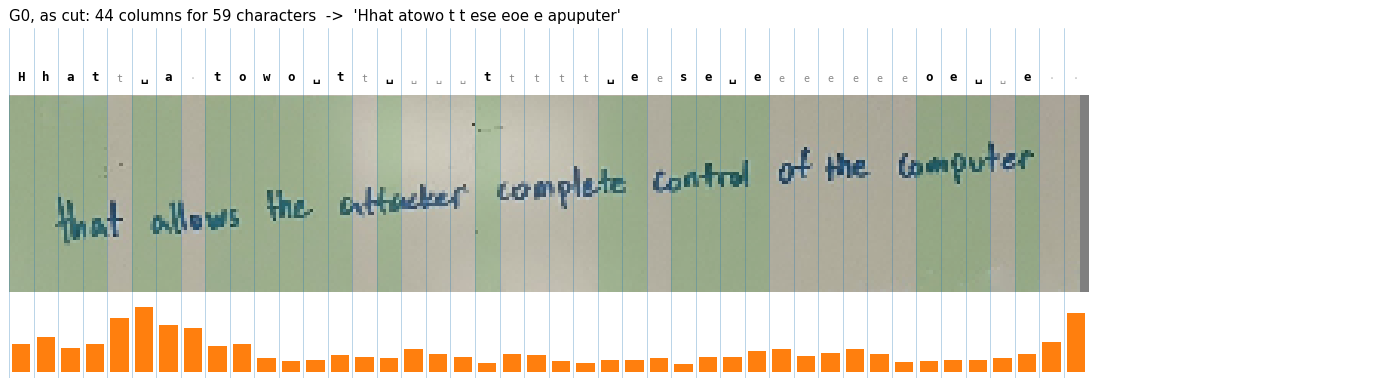

In [4]:
show_columns(img, r, f"G0, as cut: {r['ink_cols']} columns for {needed(label)} characters  ->  {r['text']!r}")

Now **widen the same crop 2×** and change nothing else: no retraining, same model. The height stays 64 px, so
the resized image is twice as wide and there are twice as many columns.

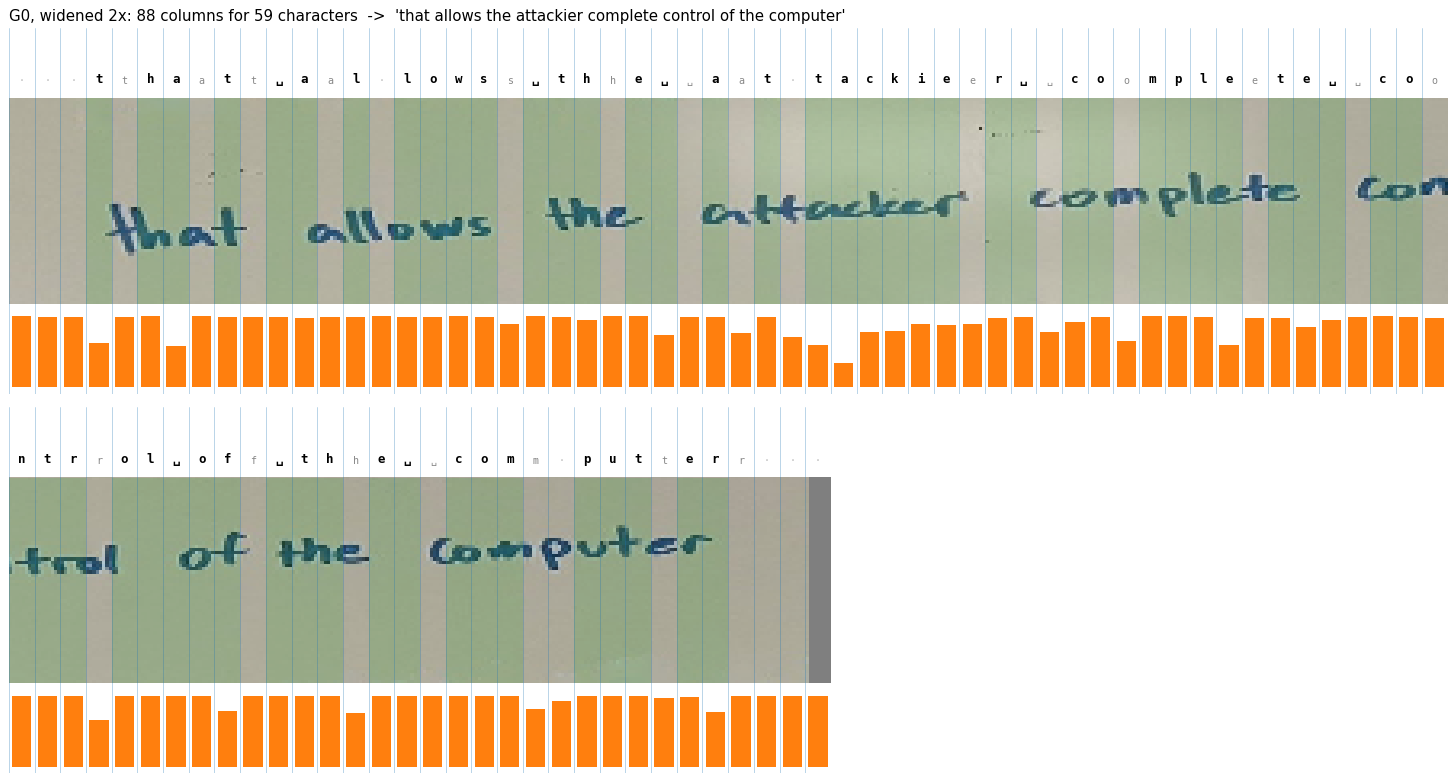

label      : that allows the attacker complete control of the computer
as cut     : Hhat atowo t t ese eoe e apuputer
widened 2x : that allows the attackier complete control of the computer


In [5]:
img2 = cv2.resize(img, (img.shape[1] * 2, img.shape[0]), interpolation=cv2.INTER_CUBIC)
r2 = ctc_columns(readers['G0'], img2)
show_columns(img2, r2, f"G0, widened 2x: {r2['ink_cols']} columns for {needed(label)} characters  ->  {r2['text']!r}")
print('label      :', label)
print('as cut     :', r['text'])
print('widened 2x :', r2['text'])

One note on the picture: each column is drawn over the 8 px strip it comes from, but the network looks at a wider
area for each column, so a letter can show up one column early or late. The column *count* is exact.

**Reading the result:**
- The model knew the letters all along. It simply had no room to write them.
- That's why most errors on new-writer crops are **deletions**, and why the P40 → P128 change (more columns) helped.

**DON'T** conclude "always widen". On the fresh boards, where crops are tight and already have plenty of room,
widening made things worse (S0: 12.4% → 23.6% at 2×). Too many columns per letter also confuses the reader. It
only helps where room is short.

## 4. A real crop with plenty of columns: wrong letters (shape confusions)

This is the second kind of error. There are enough columns, but a column picks the wrong character. The red
boxes mark the columns that wrote a different letter from the label. Below the picture are each column's top 3
guesses with their probabilities. Guidance off (G0) reduced these substitutions by about 31% on new writers. That
finding is the reason to study *where* the CTC loss acts in the backbone.

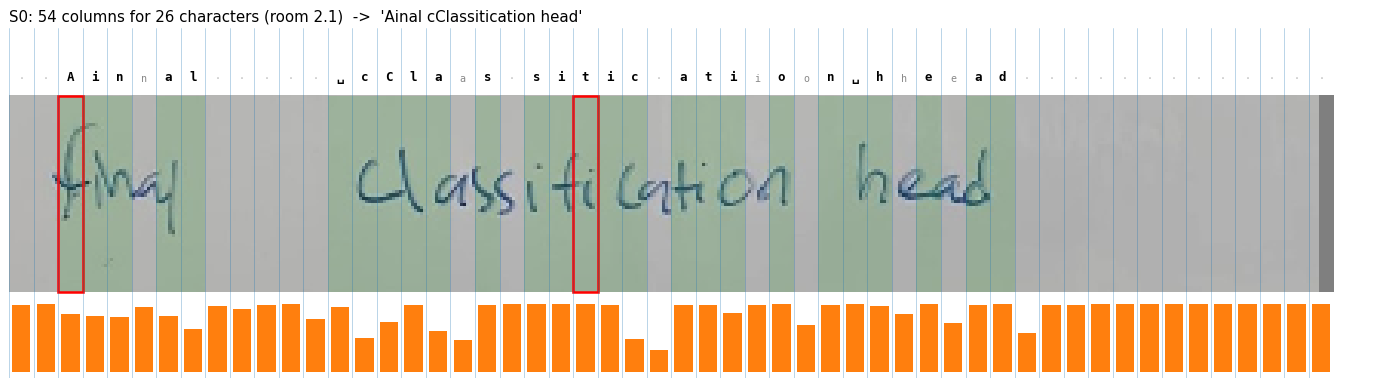

label: 'final classification head'
  column 2: wrote 'A', label has 'f'.  top 3: 'A' 0.86, 'F' 0.10, 'T' 0.01
  column 23: wrote 't', label has 'f'.  top 3: 't' 1.00, 'f' 0.00, 's' 0.00


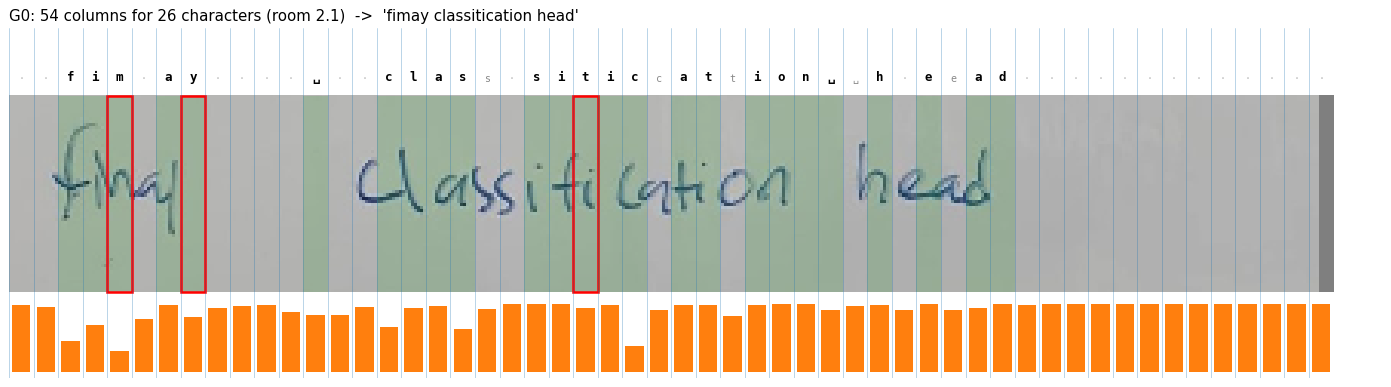

label: 'final classification head'
  column 4: wrote 'm', label has 'n'.  top 3: 'm' 0.30, 'n' 0.22, 'h' 0.15
  column 7: wrote 'y', label has 'l'.  top 3: 'y' 0.82, 't' 0.09, 'l' 0.06
  column 23: wrote 't', label has 'f'.  top 3: 't' 0.94, 'f' 0.05, 'i' 0.00


In [6]:
def substitutions(r, label):
    out = [r['table'][int(r['idx'][i])] for i in r['emit']]
    sm = difflib.SequenceMatcher(None, [c.lower() for c in out], list(' '.join(label.lower().split())), autojunk=False)
    subs = []
    for op, a0, a1, b0, b1 in sm.get_opcodes():
        if op == 'replace' and a1 - a0 == b1 - b0:
            subs += [(r['emit'][a0 + k], out[a0 + k], ' '.join(label.split())[b0 + k]) for k in range(a1 - a0)]
    return subs


key = 'images/ds__train__1.4.4.jpg'
img = cv2.imread(str(NW / key)); label = new_writers[key]
for m in ('S0', 'G0'):
    r = ctc_columns(readers[m], img)
    subs = substitutions(r, label)
    show_columns(img, r, f"{m}: {r['ink_cols']} columns for {needed(label)} characters (room {r['ink_cols'] / needed(label):.1f})  ->  {r['text']!r}",
                 mark={c for c, _, _ in subs})
    print(f'label: {label!r}')
    for c, got, want in subs:
        print(f"  column {c}: wrote {got!r}, label has {want!r}.  top 3: {topk(r, c)}")

Here the columns are fine, so the problem is how the model tells letter shapes apart. The usual confusions on
new writers are f→t, c→e, d→t/s/b and a↔e/o. This is the error type the routing experiment has to target. Letters
lost to too few columns (section 3) can't be fixed by any loss routing, because they're a geometry limit.

## 5. The real app on a fresh photo

Everything above used crops cut by hand. Here are the **app's own boxes** on the same photos: its detector and line
grouping, at the settings the app uses.
- **Green** = the labelled lines (hand-checked).
- **Red** = the app's boxes as it is now.
- **Blue** = the app's detector run on the photo shrunk to 960 px (the possible fix).

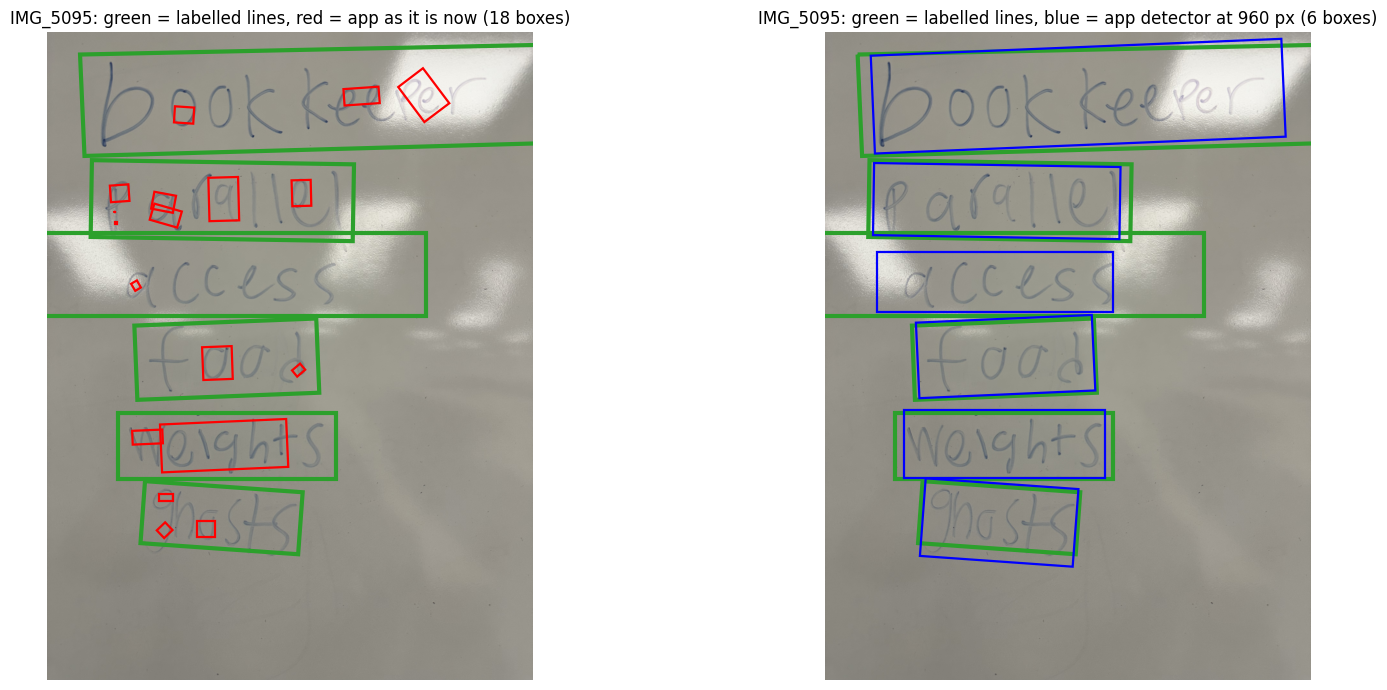

**G0 readings on IMG_5095** (error rate in brackets)

| Line (label) | Hand-cut crop | App as it is now | App at 960 px |
|---|---|---|---|
| bookkeeper | bookkeeeer (10%) |  20  (100%) | bookkeeeer (10%) |
| parallel | Parallel (0%) |  S   n a 0 (100%) | Parallel (0%) |
| access | dccess (17%) |  (100%) | dCCess (17%) |
| food | fogd (25%) | 0  (100%) | fugd (50%) |
| weights | we1ghts (14%) |  e19ht (57%) | Woigh+s (29%) |
| ghosts | 9husts (33%) |   U (100%) | ghosts (0%) |

In [7]:
man = [row for row in csv.DictReader(open(FR / 'manifest.csv', encoding='utf-8'))]
byid = {row['id']: row for row in man}
app = json.load(open(DIAG / 'app_crops' / 'app_boxes.json'))
app960 = json.load(open(DIAG / 'app_crops' / 'app_boxes960.json'))
match = json.load(open(DIAG / 'app_crops' / 'match.json'))
match960 = json.load(open(DIAG / 'app_crops' / 'match960.json'))
rows_app = json.load(open(DIAG / 'app_crops' / 'app_rows.json'))
rows_960 = json.load(open(DIAG / 'app_crops' / 'app_rows960.json'))
tight = {(x['model'], x['id']): dict(pred=x['pred'], cer=float(x['cer'])) for x in csv.DictReader(open(FR / 'scores_server_models.csv', encoding='utf-8'))}
photo_img = {}


def show_photo(ph):
    img = ob.load_image(PHOTOS / f'{ph}.HEIC'); photo_img[ph] = img
    fig, ax = plt.subplots(1, 2, figsize=(18, 7))
    for a, boxes, col, name in ((ax[0], app[ph], 'red', 'app as it is now'), (ax[1], app960[ph], 'blue', 'app detector at 960 px')):
        a.imshow(img[:, :, ::-1])
        for row in man:
            if row['photo'] == ph and row['quad']:
                a.add_patch(Polygon(json.loads(row['quad']), fill=False, ec='#2ca02c', lw=3))
        for q in boxes:
            a.add_patch(Polygon(q, fill=False, ec=col, lw=1.6))
        a.set_title(f'{ph}: green = labelled lines, {col} = {name} ({len(boxes)} boxes)'); a.axis('off')
    plt.tight_layout(); plt.show()


def line_table(ph, model='G0'):
    t = ['| Line (label) | Hand-cut crop | App as it is now | App at 960 px |', '|---|---|---|---|']
    for row in man:
        if row['photo'] != ph or row['included'] != 'yes':
            continue
        a = next(x for x in rows_app if x['id'] == row['id'] and x['model'] == model)
        b = next(x for x in rows_960 if x['id'] == row['id'] and x['model'] == model)
        h = tight[(model, row['id'])]
        t.append(f"| {row['label']} | {h['pred']} ({100 * h['cer']:.0f}%) | {a['pred']} ({100 * a['app']:.0f}%) | {b['pred']} ({100 * b['app']:.0f}%) |")
    display(Markdown(f'**{model} readings on {ph}** (error rate in brackets)\n\n' + '\n'.join(t)))


show_photo('IMG_5095'); line_table('IMG_5095')

Board A is six large words written with a thin pen. The app's normal path does this:
1. It first scans a 1600 px copy of the photo. There it only finds small bits of letters.
2. The bits are small, so it decides the writing is small and scans again at **full resolution**.
3. At full resolution the thin strokes break apart even more, so each word becomes several small boxes.
4. The reader gets single letters or half-words, and joining them gives nonsense.

At 960 px the strokes are thick enough to join, and every word comes back as one box.

Here are the actual pieces the app cut for one word, each read by G0:

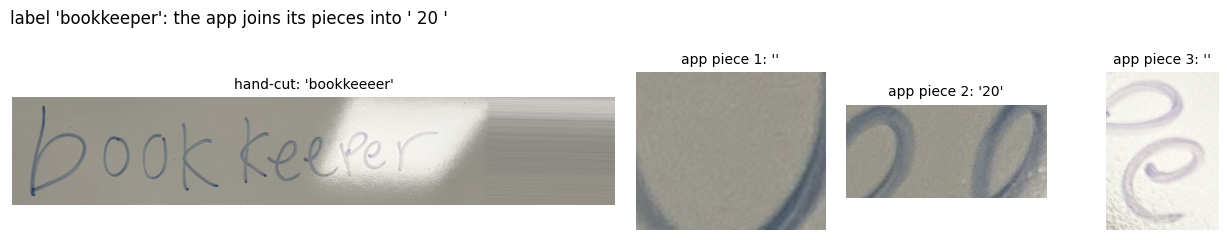

In [8]:
def show_pieces(line_id, model='G0'):
    row = byid[line_id]; ph = row['photo']; img = photo_img.get(ph)
    if img is None:
        img = ob.load_image(PHOTOS / f'{ph}.HEIC'); photo_img[ph] = img
    boxes = sorted(match[line_id]['boxes'], key=lambda b: np.mean([p[0] for p in app[ph][b]]))
    hand = cv2.imread(str(FR / row['file']))
    pieces = [tl.quad_crop(img, np.asarray(app[ph][b], dtype=np.float32)) for b in boxes]
    texts = [t['text'] for t in readers[model].read([hand] + pieces)]
    n = len(pieces) + 1
    fig, ax = plt.subplots(1, n, figsize=(min(18, 3.2 * n), 2.4), gridspec_kw=dict(width_ratios=[3] + [1] * len(pieces)))
    ax = np.atleast_1d(ax)
    ax[0].imshow(hand[:, :, ::-1]); ax[0].set_title(f'hand-cut: {texts[0]!r}', fontsize=10)
    for k, (p, t) in enumerate(zip(pieces, texts[1:]), 1):
        ax[k].imshow(p[:, :, ::-1]); ax[k].set_title(f'app piece {k}: {t!r}', fontsize=10)
    for a in ax: a.axis('off')
    plt.suptitle(f"label {row['label']!r}: the app joins its pieces into {' '.join(texts[1:])!r}", x=0.01, ha='left')
    plt.tight_layout(); plt.show()


first_split = next(k for k, v in match.items() if byid[k]['photo'] == 'IMG_5095' and len(v['boxes']) > 1)
show_pieces(first_split)

For contrast, board D is sentences in normal-size writing. Here the app's boxes already fit the lines well.

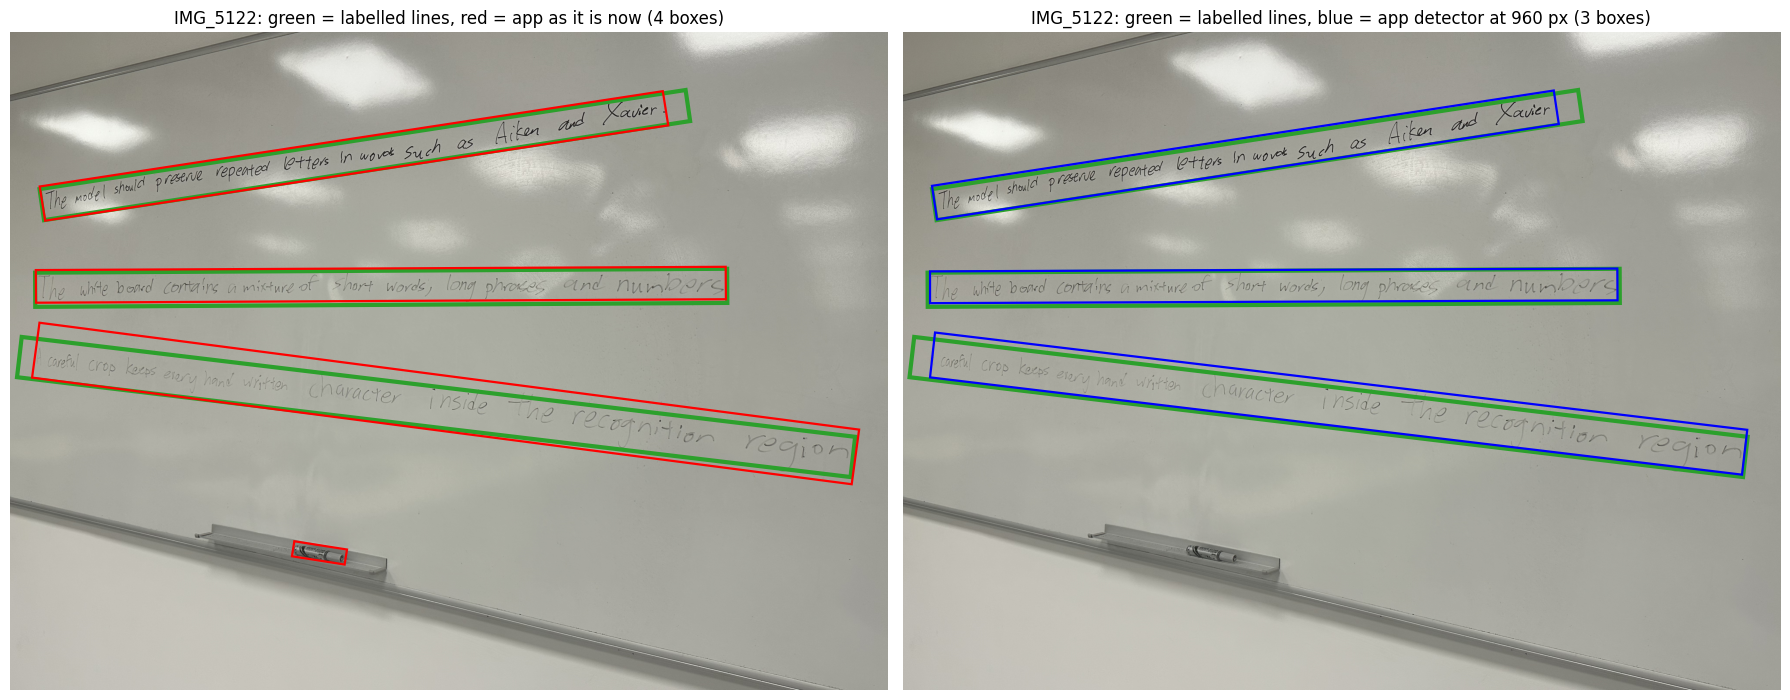

**G0 readings on IMG_5122** (error rate in brackets)

| Line (label) | Hand-cut crop | App as it is now | App at 960 px |
|---|---|---|---|
| The model should preserve repeated letters in words such as Aiken and Xavier. | The model should presevue vepeated lotters ln wovok such as Aiken and Xavier. (10%) | The model should preserue repeated letters in wovok such as Aiken and Xavier. (5%) | The model should preserue vepeated lettevs in wovok such as Aiken and Xavier. (8%) |
| The white board contains a mixture of short words, long phrases and numbers | The white boord contains a mixture of short words, long phraces and nunbors (5%) | The white booard contains a mixture of short wovds, long phrases and numnloors (8%) | The white bonrd contains a mixture of short wovds, long phroses and nusbors (7%) |
| A careful crop keeps every hand written character inside the recognition region | A careful crop keeps erery hand writrten character inside the recognition region (3%) | Acareful ro keaser and witen character inside the recognition region (15%) | careful crop keeps every hand written character inside the recognition region (3%) |

In [9]:
show_photo('IMG_5122'); line_table('IMG_5122')

## 6. All fresh-board numbers in one table

Mean line error rate (%) over the 152 fresh-board lines, the same lines and labels throughout.
- "Hand-cut" = crops cut and checked by hand.
- "App" = the app's own boxes.

In [10]:
def mean(xs): return 100 * sum(xs) / len(xs) if xs else float('nan')
t = ['| Reader | Hand-cut crops | App as it is now | App detector at 960 px |', '|---|---|---|---|']
for m, members in (('S0 (2 seeds)', ('S0', 'S0s2')), ('G0 (2 seeds)', ('G0', 'G0s2')), ('S1his', ('S1his',))):
    h = [x['tight'] for x in rows_app if x['model'] in members]
    a = [x['app'] for x in rows_app if x['model'] in members]
    b = [x['app'] for x in rows_960 if x['model'] in members]
    t.append(f'| {m} | {mean(h):.1f} | {mean(a):.1f} | {mean(b):.1f} |' if b else f'| {m} | {mean(h):.1f} | {mean(a):.1f} | not read |')
kinds = collections.Counter('merged' if v['merged'] else ('missed' if not v['boxes'] else ('one box' if len(v['boxes']) == 1 else 'split'))
                            for k, v in match.items() if v['included'] == 'yes')
kinds960 = collections.Counter('merged' if v['merged'] else ('missed' if not v['boxes'] else ('one box' if len(v['boxes']) == 1 else 'split'))
                               for k, v in match960.items() if v['included'] == 'yes')
display(Markdown('\n'.join(t) + f"\n\nApp boxes per labelled line, as it is now: {dict(kinds)};  at 960 px: {dict(kinds960)}"))

| Reader | Hand-cut crops | App as it is now | App detector at 960 px |
|---|---|---|---|
| S0 (2 seeds) | 12.4 | 31.2 | not read |
| G0 (2 seeds) | 9.1 | 26.6 | 9.6 |
| S1his | 4.6 | 28.9 | 5.3 |

App boxes per labelled line, as it is now: {'split': 35, 'one box': 115, 'merged': 2};  at 960 px: {'one box': 151, 'split': 1}

## What this shows

1. **Too few columns → letters dropped** (sections 2–3). This is a geometry limit, and training can't fix it. It
   hits tall or loosely cut crops and cramped writing. Widening only helps where room is short.
2. **Enough columns, wrong letter** (section 4). These are shape confusions. Guidance off (the CTC gradient
   reaching the backbone) reduces them, so this is what the routing experiment should target.
3. **The app's line cutting** (sections 5–6) costs more than both on large, thin-pen writing. The detector at 960 px
   brings the app close to hand-cut quality on these photos.
   - **But** that setting was found on these same photos. It has to be checked on photos with small writing
     (the frozen fresh-photo confirmation and the JH full photos) before it goes into the app.